# RACE EDGE — Exploratory analysis and chronological validation

## tl;dr
- The supplied snapshot contains **30,189 horse records across 2,367 races**, from **2014-09-14 to 2017-07-16**.
- Joining on `race_id` loses no horse rows. Withdrawal codes and structurally absent split positions need explicit handling.
- On **509 held-out 2017 races**, the form model selects the winner **25.1%** of the time, versus **29.1%** for the historical market favourite. This model does **not** establish an advantage over the market.
- The dashboard supports recurring race-by-race comparison, with exactly three headline metrics and one chart per view. It is historical replay, with no live pricing or profit claims.

## Context & Methods
**Decision-maker:** an adult race-betting researcher choosing which runners merit further investigation before each race.

**Decision:** compare the independent historical-form estimate with market pricing, inspect prior runs, and put plausible candidates on a research watchlist.

**Source:** [Kaggle — Hong Kong Horse Racing Results 2014–17 Seasons](https://www.kaggle.com/datasets/lantanacamara/hong-kong-horse-racing). The dataset page credits data scraped from **The Hong Kong Jockey Club** and lists its licence as **Unknown**, with update frequency **Not specified**. The supplied CSVs match its filenames, size and sample records. Period and counts below come from the actual files, rather than the page's older 2014–16/1,561-race description. The upstream collection has not been independently audited.

### Key Assumptions
- The CSVs contain historical race observations, not a synthetic dataset. No independent audit of the upstream collection was available.
- Model features may use current entry attributes and results strictly before the race day. All trainer and jockey statistics are frozen at the day boundary.
- Historical `win_odds` are reference observations with an unknown timestamp, and never a model feature. Reciprocal odds are normalized within each race.
- Known non-finishers remain losses; withdrawals, no-part and unknown-starter rows are removed. Races with multiple first-place horses are excluded from modelling/evaluation.
- Training ends July 2016. September–December 2016 sets a probability temperature. The 2017 window is untouched during fitting and calibration. Earlier completed test days may update historical features for later test days.
- A probability gap is a disagreement, not expected return. There is no usable pre-bet price timestamp or complete dividend data for a profit backtest.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'racing_model.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from racing_model import load_sources, prepare_features, FEATURES, build_artifacts
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15, 'font.size': 11})
horses, races = load_sources()
display(pd.DataFrame({'source':['Horse records','Races'],'rows':[len(horses),len(races)],'columns':[horses.shape[1],races.shape[1]]}))

,source,rows,columns
0,Horse records,30189,19
1,Races,2367,12


## Data
### Grain, schema and data quality
Horse rows are entries in a race, keyed by `(race_id, horse_id)`; race rows are keyed by `race_id`. The dashboard reads a single compact derived prediction CSV.

In [2]:
schema = pd.DataFrame({'column':horses.columns, 'dtype':horses.dtypes.astype(str).values, 'NA_or_placeholder':[(horses[c].isna() | horses[c].isin(['', '-', '---', 'NA'])).sum() for c in horses]})
display(schema)
checks = {'race IDs unique': bool(races.race_id.is_unique), 'horse–race keys unique': not bool(horses.duplicated(['race_id','horse_id']).any()), 'unmatched horse records': int((~horses.race_id.isin(races.race_id)).sum()), 'exact duplicate horse rows': int(horses.duplicated().sum())}
display(pd.Series(checks, name='Quality check'))
display(horses[['race_id','horse_name','finishing_position','jockey','trainer']].head(5))

,column,dtype,NA_or_placeholder
0,finishing_position,str,2
1,horse_number,str,338
2,horse_name,str,0
3,horse_id,str,0
4,jockey,str,29
5,trainer,str,0
6,actual_weight,str,2
7,declared_horse_weight,str,103
8,draw,str,591
9,length_behind_winner,str,3042


race IDs unique               True
horse–race keys unique        True
unmatched horse records          0
exact duplicate horse rows       0
Name: Quality check, dtype: object

,race_id,horse_name,finishing_position,jockey,trainer
0,2014-001,DOUBLE DRAGON,1,B Prebble,D Cruz
1,2014-001,PLAIN BLUE BANNER,2,D Whyte,D E Ferraris
2,2014-001,GOLDWEAVER,3,Y T Cheng,Y S Tsui
3,2014-001,SUPREME PROFIT,4,J Moreira,C S Shum
4,2014-001,THE ONLY KID,5,Z Purton,K W Lui


### Coverage and distance distribution

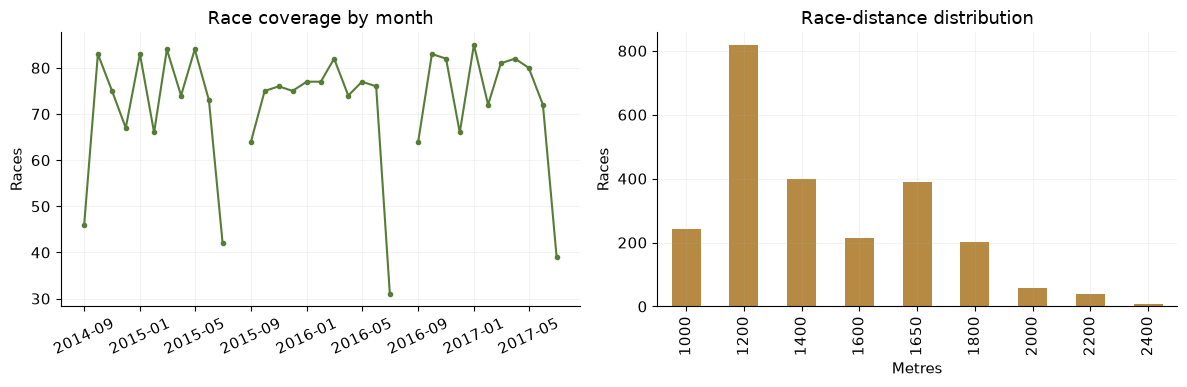

,races,first_date,last_date
race_course,,,
Happy Valley,854,2014-10-19,2017-07-12
Sha Tin,1513,2014-09-14,2017-07-16


In [3]:
monthly = races.groupby(races.race_date.dt.to_period('M')).size()
full_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq='M')
monthly = monthly.reindex(full_months)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly.index.to_timestamp(), monthly.values, marker='.', color='#567d36')
axes[0].set(title='Race coverage by month', ylabel='Races')
axes[0].tick_params(axis='x', rotation=25)
races.race_distance.value_counts().sort_index().plot.bar(ax=axes[1], color='#b68a42')
axes[1].set(title='Race-distance distribution', xlabel='Metres', ylabel='Races')
plt.tight_layout(); plt.show()
display(races.groupby('race_course').agg(races=('race_id','size'), first_date=('race_date','min'), last_date=('race_date','max')))

August has no race observations in the snapshot. Empty months are shown as gaps rather than zero performance. The first and last months are partial. Race distance is unevenly represented, so pooled completion-time comparisons would be misleading.

### Position codes and market relationship

,Rows
Result code,
WV-A,102
4 DH,35
PU,29
UR,26
3 DH,20
5 DH,18
WX,16
2 DH,14
6 DH,14


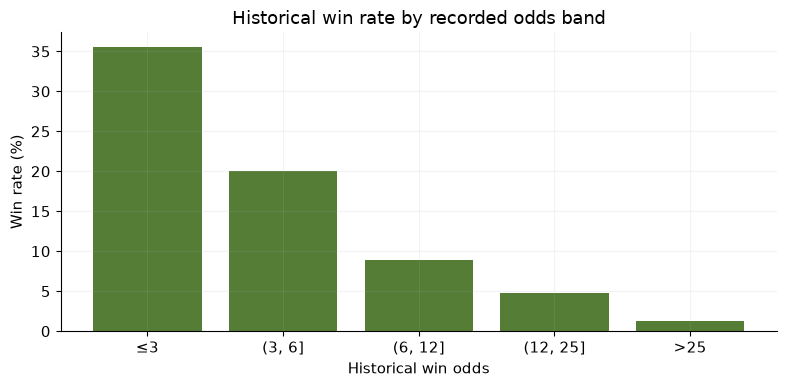

,starts,wins,win_rate
odds_band,,,
≤3,1365,486,0.356044
"(3, 6]",3973,794,0.199849
"(6, 12]",7231,640,0.088508
"(12, 25]",6356,302,0.047514
>25,10590,139,0.013126


Eligible races: 2361 | Excluded races: 6


In [4]:
display(horses.finishing_position.value_counts().rename_axis('Result code').to_frame('Rows').tail(22))
features = prepare_features(horses, races)
eligible = features.loc[features.eligible].copy()
eligible['odds_band'] = pd.cut(eligible.win_odds, [0,3,6,12,25,100], labels=['≤3','(3, 6]','(6, 12]','(12, 25]','>25'])
odds_groups = eligible.groupby('odds_band', observed=True).agg(starts=('won','size'), wins=('won','sum'))
odds_groups['win_rate'] = odds_groups.wins / odds_groups.starts
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(odds_groups.index.astype(str), odds_groups.win_rate * 100, color='#567d36')
ax.set(title='Historical win rate by recorded odds band', xlabel='Historical win odds', ylabel='Win rate (%)')
plt.tight_layout(); plt.show()
display(odds_groups)
print('Eligible races:', eligible.race_id.nunique(), '| Excluded races:', races.race_id.nunique() - eligible.race_id.nunique())

Historical prices provide a meaningful baseline, but their recording time is unknown. This descriptive relationship does not prove that a tradable betting advantage existed.

## Results
### Reproduce the model and inspect held-out performance
The next cell rebuilds all committed artifacts deterministically; it uses no current-race finish information or odds as features.

In [5]:
test, model_report = build_artifacts(verbose=False)
display(pd.DataFrame(model_report['metrics']).T.round(4))
assert abs(test.groupby('race_id').model_probability.sum() - 1).max() < 1e-8
assert abs(test.groupby('race_id').market_probability.sum() - 1).max() < 1e-8
assert test.race_date.min() > pd.Timestamp('2016-12-31')
assert not {'finish_rank','finish_time','finishing_position','won','win_odds','running_position_1'}.intersection(FEATURES)
print('Temporal windows and probability sums checked.')

,races,top1_hits,top1_accuracy,top3_coverage,log_loss,brier
Form model,509.0,128.0,0.2515,0.5501,2.2021,0.0693
Closing market,509.0,148.0,0.2908,0.6326,1.9910,0.0659
Uniform,509.0,44.0,0.0864,0.2024,2.5021,0.0743


Temporal windows and probability sums checked.


### Monthly validation — weighted totals, not averages of monthly percentages

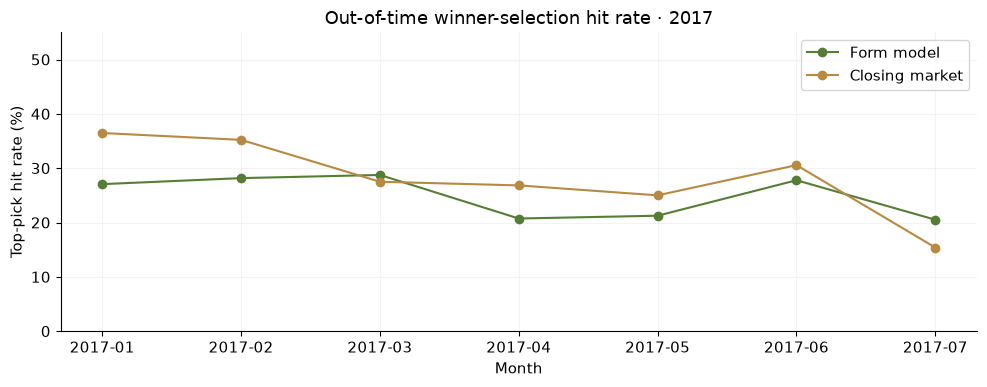

,month,model,races,top1_hits,top1_accuracy
0,2017-01,Form model,85,23,0.2706
1,2017-01,Closing market,85,31,0.3647
2,2017-02,Form model,71,20,0.2817
3,2017-02,Closing market,71,25,0.3521
4,2017-03,Form model,80,23,0.2875
5,2017-03,Closing market,80,22,0.2750
6,2017-04,Form model,82,17,0.2073
7,2017-04,Closing market,82,22,0.2683
8,2017-05,Form model,80,17,0.2125
9,2017-05,Closing market,80,20,0.2500


In [6]:
monthly_results = pd.DataFrame(model_report['monthly'])
fig, ax = plt.subplots(figsize=(10,4))
for name, color in [('Form model','#567d36'),('Closing market','#b68a42')]:
    group = monthly_results.loc[monthly_results.model.eq(name)]
    ax.plot(group.month, group.top1_accuracy * 100, marker='o', label=name, color=color)
ax.set(title='Out-of-time winner-selection hit rate · 2017', xlabel='Month', ylabel='Top-pick hit rate (%)', ylim=(0,55))
ax.legend(); plt.tight_layout(); plt.show()
display(monthly_results[['month','model','races','top1_hits','top1_accuracy']].round(4))

## Takeaways
1. A polished interface can support repeat comparisons without claiming to beat the market. In the independent 2017 window, the historical-form model records **128/509** winning top picks, while the odds favourite records **148/509**.
2. Use three headline values: top-pick model win probability, recorded historical odds, and the model–market probability gap. Show the field comparison before runner detail.
3. Exclude raw finish-time rankings and profit/ROI panels: distances differ, and reliable executable odds/dividends/fees are unavailable. Exclude raw incident narratives from the main view because they overwhelm the repeated comparison task.
4. A production implementation would refresh historical features after official result confirmation, refresh pre-race odds every 60 seconds if a licensed feed permits, and suspend stale price comparisons after 120 seconds. These are design assumptions; this snapshot does not update.
5. No currently upcoming race has been predicted here: this is an out-of-time historical replay and a course prototype. Upstream data provenance/licence, live integrations and an independent future evaluation remain open production questions.